# 03_Temporal_features_Analysis

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
df=pd.read_csv(r'D:\new Projects\appliance-energy-forecasting\data\raw\energydata_complete.csv')

In [14]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [19]:
df['date'].dtype

dtype('O')

In [23]:
df['date']=pd.to_datetime(df['date'])
df['date'].dtype

dtype('<M8[ns]')

## Extracting Features from Date

In [27]:
df['hour']=df['date'].dt.hour
df['minute']=df['date'].dt.minute
df['day_of_week']=df['date'].dt.dayofweek
df['day_name']=df['date'].dt.day_name()
df['is_weekend'] = (
    df['day_of_week'].isin([5, 6]).astype(int)
)
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['date_only'] = df['date'].dt.date

In [29]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'minute',
       'day_of_week', 'day_name', 'is_weekend', 'month', 'day', 'date_only'],
      dtype='object')

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 37 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[ns]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7

In [44]:
df.sample(5)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,rv1,rv2,hour,minute,day_of_week,day_name,is_weekend,month,day,date_only
11645,2016-04-01 13:50:00,50,0,22.290000,39.022500,22.890000,36.500000,22.290000,38.000000,21.20,...,22.740319,22.740319,13,50,4,Friday,0,4,1,2016-04-01
11673,2016-04-01 18:30:00,50,0,22.100000,38.163333,20.666667,38.400000,22.390000,37.590000,20.79,...,8.428281,8.428281,18,30,4,Friday,0,4,1,2016-04-01
17629,2016-05-13 03:10:00,60,0,25.033333,48.090000,23.100000,49.684286,26.600000,44.163333,25.10,...,21.102418,21.102418,3,10,4,Friday,0,5,13,2016-05-13
13790,2016-04-16 11:20:00,310,10,22.200000,43.430000,21.633333,41.826667,23.963333,39.863333,21.70,...,22.588710,22.588710,11,20,5,Saturday,1,4,16,2016-04-16
1650,2016-01-23 04:00:00,40,0,17.390000,42.590000,16.500000,42.826667,17.700000,40.790000,15.39,...,28.301094,28.301094,4,0,5,Saturday,1,1,23,2016-01-23


In [46]:
sns.set_theme(style='darkgrid')
sns.set_style()

### hour

<Axes: xlabel='hour', ylabel='Count'>

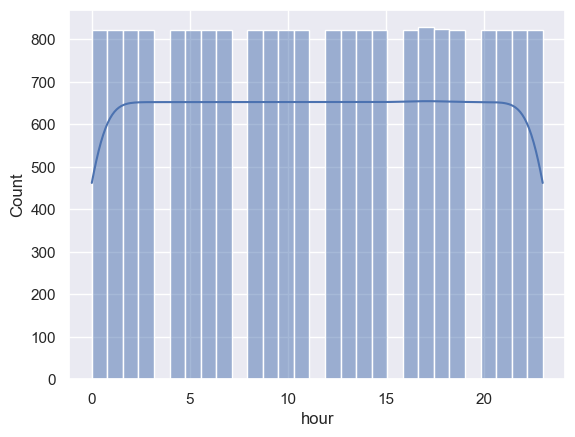

In [49]:
sns.histplot(data=df,x='hour',kde=True)

In [51]:
df['hour'].describe()

count    19735.000000
mean        11.502002
std          6.921953
min          0.000000
25%          6.000000
50%         12.000000
75%         17.000000
max         23.000000
Name: hour, dtype: float64

<Axes: xlabel='hour', ylabel='Appliances'>

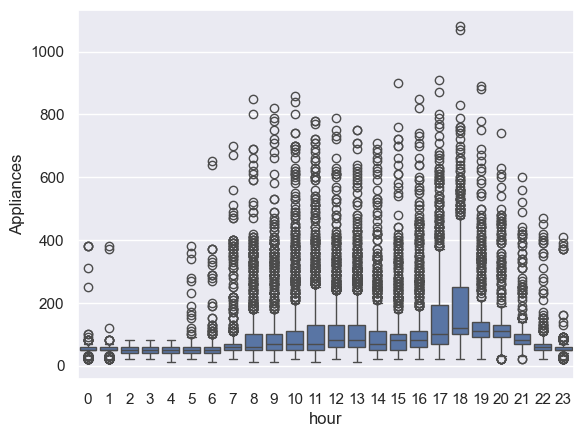

In [53]:
sns.boxplot(x='hour',y='Appliances',data=df)

In [57]:
df.groupby('hour')['Appliances'].agg(['count','mean','median','std'])

,count,mean,median,std
hour,,,,
0,822,52.785888,50.0,25.615928
1,822,51.326034,50.0,19.288647
2,822,49.075426,50.0,10.694366
3,822,48.236010,50.0,11.445056
4,822,49.355231,50.0,10.244173
5,822,52.737226,50.0,27.301297
6,822,57.712895,50.0,46.446179
7,822,78.649635,60.0,81.476935
8,822,106.143552,60.0,112.102458


#### Hourly Temporal Analysis — Key Findings
1. Appliance energy consumption exhibits a clear hourly pattern, with relatively low consumption during overnight hours.
2. Consumption begins increasing around 07:00, indicating a morning rise in appliance activity.
3. The highest average consumption occurs at 18:00 (190.36 Wh), followed by 17:00 (161.35 Wh).
4. Mean consumption is considerably higher than median consumption during peak hours, suggesting the presence of occasional high-energy consumption events.
5. Consumption variability is highest during evening hours, particularly at 17:00 and 18:00.
6. Hour of the day appears to be a potentially useful predictor for our forecasting model, although its predictive contribution must be validated experimentally.

#### day_of_week

<Axes: xlabel='day_of_week', ylabel='Appliances'>

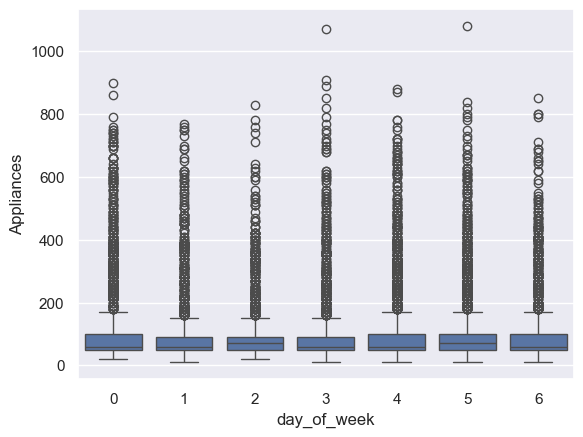

In [61]:
sns.boxplot(x='day_of_week',y='Appliances',data=df)

In [63]:
df.groupby('day_of_week')['Appliances'].agg(['min','max','mean','median','std','count'])

,min,max,mean,median,std,count
day_of_week,,,,,,
0,20,900,111.450684,60.0,122.115039,2778
1,10,770,87.125000,60.0,90.981669,2880
2,20,830,89.930556,70.0,80.734269,2880
3,10,1070,90.434028,60.0,98.314658,2880
4,10,880,104.622144,60.0,116.247164,2845
5,10,1080,106.246345,70.0,110.221565,2736
6,10,850,94.915936,60.0,90.511406,2736


#### Day-of-Week Temporal Analysis — Key Findings
1. Average appliance consumption varies across the days of the week.
2. Monday exhibits the highest mean consumption (111.45 Wh), whereas Tuesday exhibits the lowest (87.13 Wh).
3. Median consumption remains relatively consistent between 60 and 70 Wh across all days.
4. Mean values being noticeably higher than median values suggest that high-consumption events influence daily averages.
5. Monday exhibits the highest consumption variability, while Wednesday exhibits the lowest.
6. No strong or consistent weekday-versus-weekend pattern is established from these descriptive statistics alone.

#### is_weekend

<Axes: xlabel='is_weekend', ylabel='Appliances'>

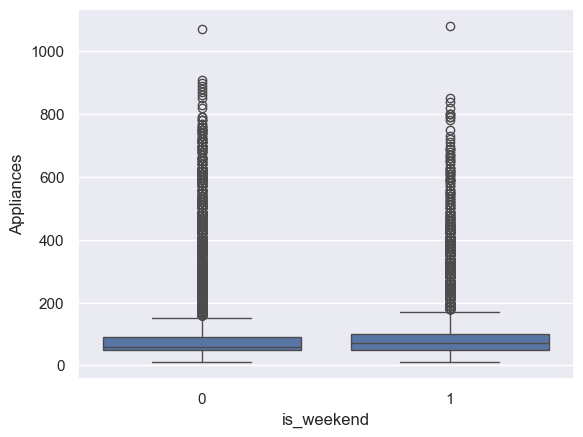

In [67]:
sns.boxplot(x='is_weekend',y='Appliances',data=df)

In [69]:
df.groupby('is_weekend')['Appliances'].agg(['min','max','mean','median','std','count'])

,min,max,mean,median,std,count
is_weekend,,,,,,
0,10,1070,96.587674,60.0,103.086372,14263
1,10,1080,100.581140,70.0,100.998987,5472


#### Weekday vs Weekend — Key Findings
1. Weekend average consumption (100.58 Wh) is slightly higher than weekday average consumption (96.59 Wh).
2. Weekend median consumption is 10 Wh higher than weekday median consumption.
3. Consumption variability is similar across weekdays and weekends.
4. Both groups exhibit comparable extreme consumption values.
5. The observed differences suggest a possible weekend consumption effect, but the difference is relatively small and requires further investigation before being considered a useful forecasting feature.

#### month

<Axes: xlabel='month', ylabel='Appliances'>

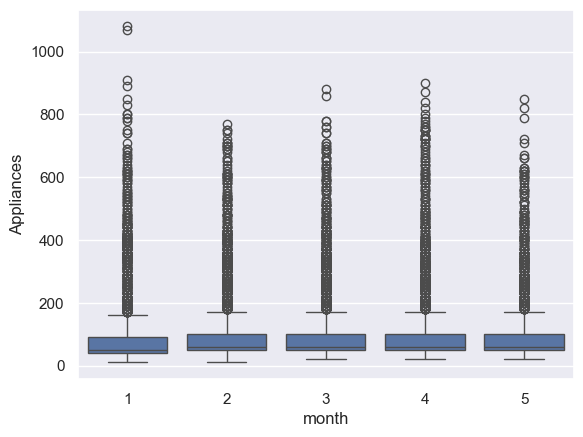

In [91]:
sns.boxplot(x='month',y='Appliances',data=df)

In [93]:
df.groupby('month')['Appliances'].agg(['min','max','mean','median','std','count'])

,min,max,mean,median,std,count
month,,,,,,
1,10,1080,97.026010,50.0,123.015094,2922
2,10,770,100.945881,60.0,102.354279,4176
3,20,880,96.953405,60.0,99.007133,4464
4,20,900,98.888889,60.0,103.896607,4320
5,20,850,94.199325,60.0,86.795158,3853


#### Monthly Temporal Analysis — Key Findings
1. Monthly average appliance consumption remains relatively stable between approximately 94 and 101 Wh.
2. February exhibits the highest mean consumption (100.95 Wh), while May exhibits the lowest (94.20 Wh).
3. Median consumption remains relatively consistent across February–May.
4. January exhibits the highest consumption variability, while May exhibits the lowest.
5. No clear monotonic monthly consumption trend is evident.
6. Monthly variation may be useful for understanding broader temporal behaviour, but its predictive contribution needs validation.

#### daily consumption

In [101]:
daily_consumption = (
    df.groupby('date_only')['Appliances']
      .agg(['mean', 'median', 'std', 'min', 'max', 'count'])
)

daily_consumption.head()

,mean,median,std,min,max,count
date_only,,,,,,
2016-01-11,136.666667,100.0,125.846726,40,580,42
2016-01-12,85.694444,50.0,96.437615,20,500,144
2016-01-13,97.013889,50.0,102.076893,20,520,144
2016-01-14,151.388889,70.0,175.704819,20,910,144
2016-01-15,125.347222,60.0,122.405455,30,500,144


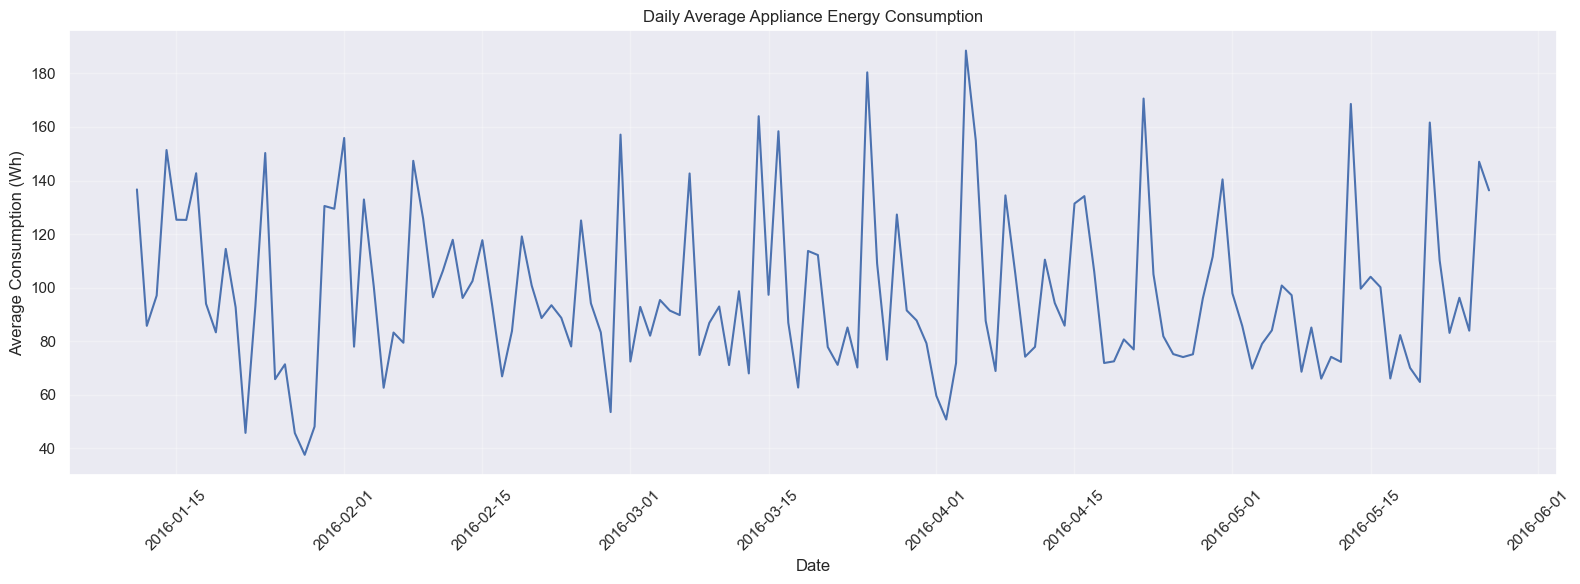

In [103]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_consumption.index,
    daily_consumption['mean']
)

plt.title('Daily Average Appliance Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Average Consumption (Wh)')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

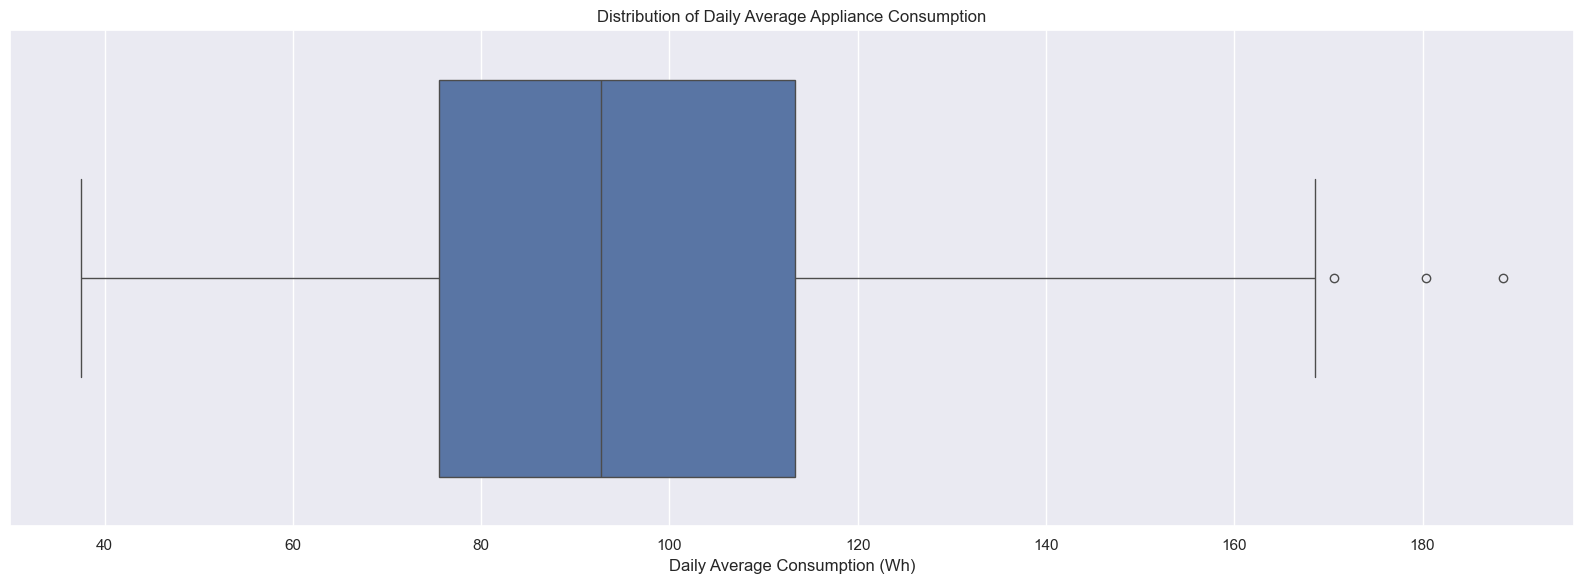

In [105]:
plt.figure(figsize=(16, 6))

sns.boxplot(
    x=daily_consumption['mean']
)

plt.title('Distribution of Daily Average Appliance Consumption')
plt.xlabel('Daily Average Consumption (Wh)')

plt.tight_layout()
plt.show()

<Axes: xlabel='day', ylabel='Appliances'>

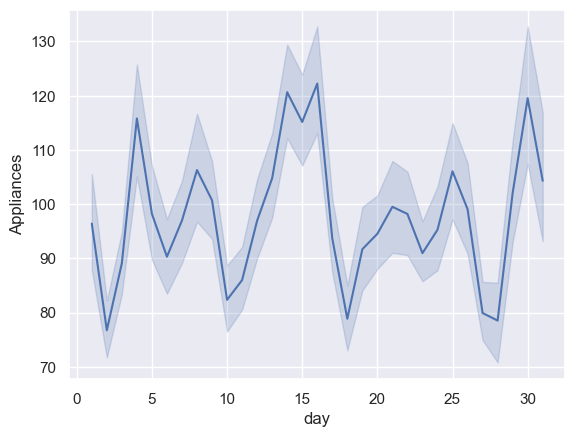

In [96]:
sns.lineplot(x='day',y='Appliances',data=df)

<Axes: xlabel='date_only', ylabel='Appliances'>

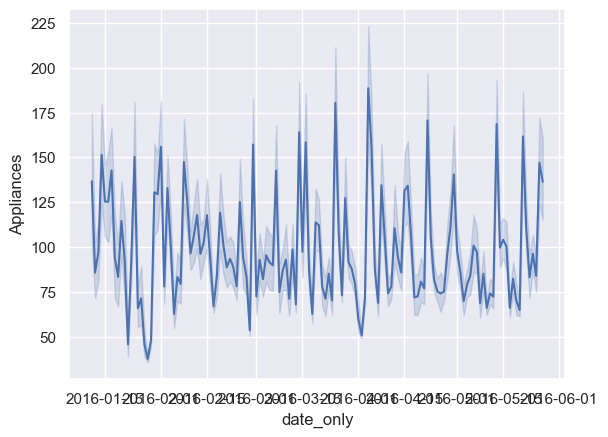

In [99]:
sns.lineplot(x='date_only',y='Appliances',data=df)

#### Daily Temporal Analysis — Key Findings
1. Daily average appliance consumption exhibits substantial fluctuations throughout the observation period.
2. Frequent peaks and troughs indicate considerable day-to-day variation in energy consumption.
3. No clear sustained upward or downward long-term trend is evident.
4. Several periods exhibit elevated daily average consumption, suggesting occasional increases in appliance usage.
5. Daily consumption patterns appear volatile, indicating that calendar date alone may not sufficiently explain short-term energy consumption.
6. Temporal features should be evaluated alongside environmental and historical consumption features during model development.

In [108]:
daily_consumption.sort_values(
    by='mean',
    ascending=False
).head(10)

,mean,median,std,min,max,count
date_only,,,,,,
2016-04-04,188.541667,90.0,191.669036,30,900,144
2016-03-25,180.416667,90.0,180.929515,30,880,144
2016-04-22,170.625000,90.0,166.124979,40,870,144
2016-05-13,168.611111,100.0,146.915185,40,660,144
2016-03-14,164.027778,90.0,169.145609,20,860,144
2016-05-21,161.666667,95.0,159.649967,40,790,144
2016-03-16,158.402778,90.0,169.060188,20,780,144
2016-02-29,157.152778,80.0,160.718070,30,700,144
2016-02-01,155.902778,70.0,157.832403,20,710,144


In [110]:
daily_consumption.sort_values(
    by='mean',
    ascending=True
).head(10)

,mean,median,std,min,max,count
date_only,,,,,,
2016-01-28,37.500000,40.0,10.544611,10,50,144
2016-01-27,45.625000,40.0,45.966220,20,390,144
2016-01-22,45.694444,40.0,47.653363,20,400,144
2016-01-29,48.055556,40.0,21.098430,10,110,144
2016-04-02,50.694444,50.0,10.880969,20,80,144
2016-02-28,53.472222,50.0,19.515798,20,150,144
2016-04-01,59.583333,50.0,52.181434,20,440,144
2016-02-05,62.569444,50.0,56.255493,20,540,144
2016-03-18,62.638889,50.0,31.820873,20,250,144


#### Peak and Low Consumption Days — Key Findings
1. Daily average consumption varies substantially across the observation period.
2. April 4, 2016, records the highest daily mean consumption at 188.54 Wh.
3. January 28, 2016, records the lowest daily mean consumption at 37.50 Wh.
4. High-consumption days generally exhibit substantial within-day variability.
5. Some low-consumption days also contain considerable fluctuations, indicating occasional high-energy events.
6. Daily mean consumption alone does not adequately describe the variability of appliance usage.
7. Identifying unusual days may help investigate consumption anomalies, but these observations should not automatically be classified as outliers.

In [113]:
df.to_csv(r'D:\new Projects\appliance-energy-forecasting\data\processed\appliances_energy_temporal_features.csv', index=False)

## Temporal Analysis — Key Findings and Insights

Temporal analysis was conducted to investigate how appliance energy consumption varies across different time dimensions using the timestamp information available in the UCI Appliances Energy Prediction dataset (January–May 2016).

### 1. Hourly Consumption Patterns

Hourly analysis revealed a distinct daily consumption pattern.

- Consumption remained relatively low and stable during overnight hours (00:00–06:00), with average consumption generally between 48 and 58 Wh.
- Consumption began increasing around 07:00, indicating a noticeable morning increase in appliance activity.
- Elevated consumption continued throughout the daytime, with another pronounced increase during the evening.
- The highest hourly mean consumption occurred at 18:00 (190.36 Wh), followed by 17:00 (161.35 Wh).
- Consumption declined progressively after 18:00.

Evening hours also exhibited substantially higher standard deviations, indicating greater variability in appliance usage during peak consumption periods.

**Insight:** Hour of the day emerged as a potentially valuable predictor for capturing recurring daily consumption behaviour.

### 2. Day-of-Week Patterns

Consumption varied across individual days of the week.

- Monday recorded the highest average consumption (111.45 Wh), while Tuesday recorded the lowest (87.13 Wh).
- Friday and Saturday also exhibited relatively elevated average consumption.
- Median consumption remained relatively consistent, ranging between 60 and 70 Wh.
- Monday exhibited the highest consumption variability, whereas Wednesday exhibited the lowest.

These differences suggest some day-specific variation, although no consistent weekday progression was established.

### 3. Weekday vs. Weekend Comparison

Weekend consumption was slightly higher than weekday consumption.

- Weekday average: 96.59 Wh.
- Weekend average: 100.58 Wh.
- Weekday median: 60 Wh.
- Weekend median: 70 Wh.

The standard deviations were similar (103.09 Wh for weekdays and 101.00 Wh for weekends).

**Insight:** Weekend status may capture a modest consumption difference, but its independent predictive contribution remains uncertain and requires validation during model development.

### 4. Monthly Consumption Patterns

Monthly analysis revealed relatively stable average consumption throughout the observation period.

- February recorded the highest monthly mean (100.95 Wh).
- May recorded the lowest monthly mean (94.20 Wh).
- Monthly means remained within a relatively narrow range of approximately 94–101 Wh.
- January exhibited the highest variability (standard deviation: 123.02 Wh), whereas May exhibited the lowest (86.80 Wh).

No clear monotonic monthly trend was identified.

Since the dataset covers only January through May, the available observations are insufficient to establish a recurring annual seasonal pattern.

### 5. Daily Consumption Trends and Anomalies

Daily average consumption exhibited considerable fluctuations throughout the observation period, with frequent peaks and troughs.

- No obvious sustained upward or downward long-term trend was identified.
- April 4, 2016, recorded the highest daily mean consumption at 188.54 Wh.
- January 28, 2016, recorded the lowest daily mean consumption at 37.50 Wh.
- High-consumption days generally exhibited substantial within-day variability.
- Some low-consumption days also contained occasional high-consumption events.

The differences between daily means and medians indicate that occasional high-energy consumption intervals can substantially influence average daily consumption.

**Insight:** Consumption variability is an important characteristic that cannot be adequately represented by average consumption alone.

### 6. Temporal Feature Importance and Forecasting Relevance

The analysis identified several temporal variables that may contribute to forecasting appliance energy consumption.

| Temporal Feature | Potential forecasting relevance |
|---|---|
| Hour | Captures recurring daily consumption patterns and peak periods |
| Minute | Identifies the position within the hourly cycle |
| Day of week | Captures possible differences in consumption across weekdays |
| Weekend indicator | Represents potential weekday–weekend behavioural differences |
| Month | Captures possible broader calendar-related variation |
| Day of month | Represents calendar position, although its independent relevance is uncertain |

Hour of the day appears to be the most promising temporal feature based on the observed descriptive patterns. Day of week and weekend indicators may provide additional information, while monthly and day-of-month features require further investigation.

Importantly, these observations represent exploratory evidence, not measured model feature importance. Actual predictive importance will be assessed through model validation and appropriate feature-importance techniques.

### 7. Overall Conclusion

Temporal analysis identified a pronounced daily consumption cycle, characterized by relatively low overnight demand, increasing morning consumption and elevated evening consumption, with the strongest average demand occurring around 18:00.

In contrast, day-of-week, weekday–weekend and monthly differences were comparatively modest and did not establish strong, consistent patterns. Daily consumption also demonstrated substantial volatility, highlighting the limitations of relying exclusively on calendar-based features.

The findings support incorporating temporal information into the forecasting pipeline, particularly hour-based features. However, temporal variables alone are unlikely to capture all consumption fluctuations.

For the next stages, temporal features will be evaluated alongside environmental sensor measurements and historical consumption information. Their final inclusion and predictive contribution will be determined through chronological validation and model performance rather than descriptive statistics alone.

The resulting temporally enriched dataset has been saved separately in `data/processed/`, preserving the original dataset for reproducibility and subsequent experimentation.